# 🎬 Movie Recommendation System — UneeQ Interns ML Task

**Goal:** a content/product platform wants to suggest relevant items to users. We build a recommender with
1. a **popularity baseline**,
2. **content-based** and **collaborative filtering** (Item-KNN and SVD) models,
3. a **cold-start aware hybrid** for new users,
4. **ranking evaluation** (Precision / Recall / NDCG / MAP / HitRate @10, coverage, novelty),
5. **explanations** for every recommendation.

Dataset: [MovieLens 100K](https://grouplens.org/datasets/movielens/100k/) — 100,000 ratings (1–5★) from 943 users on 1,682 movies.

All model code lives in `src/` so the notebook, the evaluation scripts and the Streamlit demo share exactly the same logic.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.data import load, temporal_split, GENRES
from src.models import (PopularityRecommender, ContentBasedRecommender, ItemKNNRecommender,
                        SVDRecommender, make_hybrid, all_models)
from src.evaluate import evaluate_warm, evaluate_cold

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
# fixed colour per model (identity never changes between charts); baseline in neutral grey
COLORS = {"Hybrid (cold-start aware)": "#2a78d6", "SVD (matrix factorisation)": "#eb6834",
          "Item-KNN CF": "#1baf7a", "Content-based": "#eda100", "Popularity": "#8a8984"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True,"grid.color": "#e6e5e0", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#b8b7b0", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10})
pd.set_option("display.precision", 4)

## 1. Data exploration

In [2]:
ml = load()
r = ml.ratings
print(f"{len(r):,} ratings | {ml.n_users} users | {ml.n_items} movies")
print(f"Sparsity: {1 - len(r) / (ml.n_users * ml.n_items):.1%} of the user x movie matrix is empty")
ml.items[["title", "year", "genre_list"]].head()

100,000 ratings | 943 users | 1682 movies
Sparsity: 93.7% of the user x movie matrix is empty


,title,year,genre_list
0,Toy Story (1995),1995.0,"[Animation, Children's, Comedy]"
1,GoldenEye (1995),1995.0,"[Action, Adventure, Thriller]"
2,Four Rooms (1995),1995.0,[Thriller]
3,Get Shorty (1995),1995.0,"[Action, Comedy, Drama]"
4,Copycat (1995),1995.0,"[Crime, Drama, Thriller]"


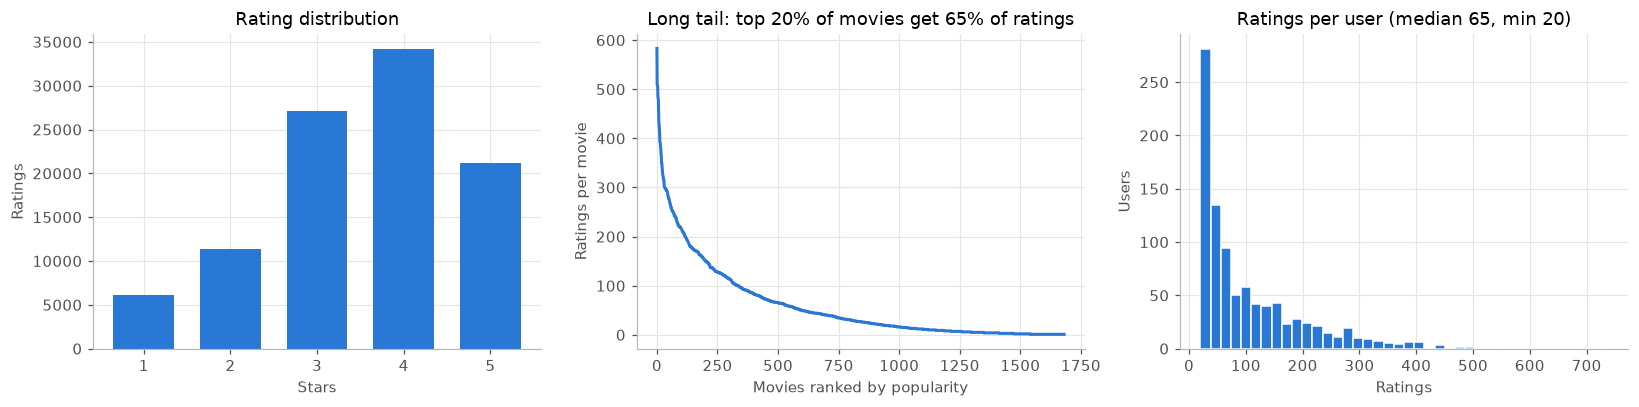

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

dist = r["rating"].value_counts().sort_index()
axes[0].bar(dist.index, dist.values, color="#2a78d6", width=0.7)
axes[0].set(title="Rating distribution", xlabel="Stars", ylabel="Ratings")

pop = r.groupby("item_id").size().sort_values(ascending=False).to_numpy()
axes[1].plot(np.arange(len(pop)), pop, color="#2a78d6", lw=2)
share = pop[: int(len(pop) * 0.2)].sum() / pop.sum()
axes[1].set(title=f"Long tail: top 20% of movies get {share:.0%} of ratings",
            xlabel="Movies ranked by popularity", ylabel="Ratings per movie")

per_user = r.groupby("user_id").size()
axes[2].hist(per_user, bins=40, color="#2a78d6", edgecolor="white", linewidth=1)
axes[2].set(title=f"Ratings per user (median {per_user.median():.0f}, min {per_user.min()})",
            xlabel="Ratings", ylabel="Users")
plt.tight_layout(); plt.savefig(FIG / "eda.png", bbox_inches="tight"); plt.show()

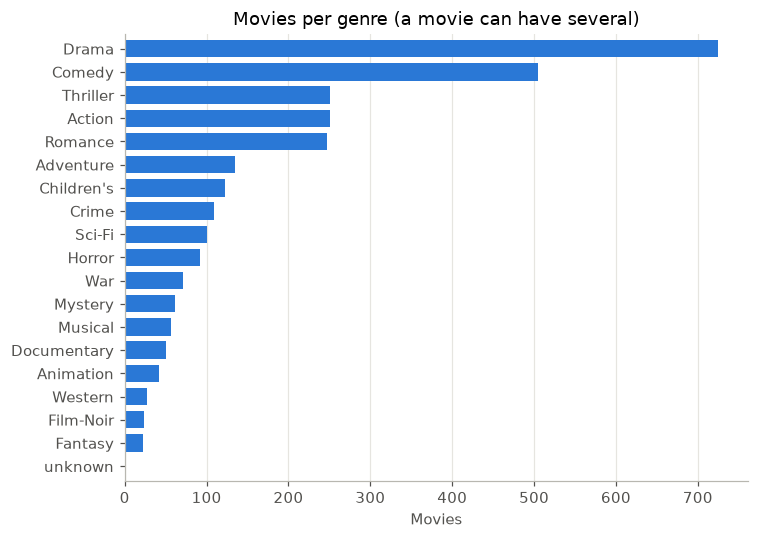

In [4]:
genre_counts = ml.items[GENRES].sum().sort_values()
ax = genre_counts.plot.barh(figsize=(7, 5), color="#2a78d6", width=0.75)
ax.set(title="Movies per genre (a movie can have several)", xlabel="Movies"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Takeaways:** ratings skew positive (4★ is most common), the data is ~94% sparse, and popularity is a long tail —
a handful of blockbusters collect most ratings. That makes a popularity baseline surprisingly strong and is why we
also track **coverage** and **novelty**: a good recommender should beat the baseline *without* only showing blockbusters.

## 2. Evaluation protocol

* **Existing ("warm") users** — for every user, the *oldest* 80% of their ratings are training data and the *most recent*
  20% are the test set. We predict the future rather than random gaps, which is what a real platform faces.
* **Relevant item** = a held-out movie the user rated **≥ 4★**. Each model returns a top-10 list of movies the user has not rated.
* **New ("cold-start") users** — 20% of users are removed from training entirely. We reveal only their first *n* ratings
  (n = 0, 1, 3, 5, 10, 20; n = 0 means we only know age group and gender from sign-up) and rank the rest.
  These users are split in half: one half is used **only for tuning**, the other **only for the final numbers below**.

In [5]:
split = temporal_split(ml.ratings)
print(f"Train: {len(split.train):,} ratings | Test: {len(split.test):,} ratings | "
      f"cold-start users: {len(split.cold_val_users)} tuning + {len(split.cold_test_users)} test")

Train: 64,794 ratings | Test: 15,831 ratings | cold-start users: 94 tuning + 94 test


## 3. Models

| Model | Idea | Explanation shown to the user |
|---|---|---|
| **Popularity** (baseline) | Most-rated movies, same list for everyone | "Popular: rated by N users" |
| **Content-based** | IDF-weighted genres + release decade; the user profile is the sum of rated movies weighted by (rating − 3) | "Matches your favourite genres: …" |
| **Item-KNN CF** | Cosine similarity between movies (who rated them), top-50 neighbours; score = Σ (rating − 2.5) · similarity | "Because you liked X and Y" |
| **SVD** | PureSVD matrix factorisation (50 latent factors); new profiles are folded in without retraining | via the nearest liked movies |
| **Hybrid** | `a·CF + (1−a)·(b·content + (1−b)·demographic popularity)`, with `a = n/(n+n0)` growing with the number of ratings n | combines the reasons above |

Every model scores a *profile* `{movie: rating}`, so the same code serves existing users, new users and the demo app.

In [6]:
models = all_models()
for m in models.values():
    m.fit(split.train, ml)
print("Hybrid config (tuned on validation users):", json.loads((ROOT / "reports" / "best_hybrid.json").read_text()))

Hybrid config (tuned on validation users): {'cf': 'svd', 'n0': 5.0, 'content_weight': 0.3, 'pop_floor': 0.1}


## 4. Results — existing users

In [7]:
warm = evaluate_warm(models, split, ml, k=10)
warm.style.format("{:.4f}").highlight_max(color="#d7e7fa", subset=warm.columns[:5])

,Precision@10,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage,Novelty
Model,,,,,,,
Popularity,0.0769,0.0839,0.0989,0.0466,0.4437,0.0434,7.7524
Content-based,0.0177,0.0151,0.0229,0.0090,0.1484,0.6480,12.0420
Item-KNN CF,0.1228,0.1409,0.1667,0.0908,0.5742,0.2735,8.6813
SVD (matrix factorisation),0.1227,0.1605,0.1734,0.0909,0.6168,0.2973,8.8230
Hybrid (cold-start aware),0.1264,0.1614,0.1822,0.0997,0.6099,0.2747,8.5959


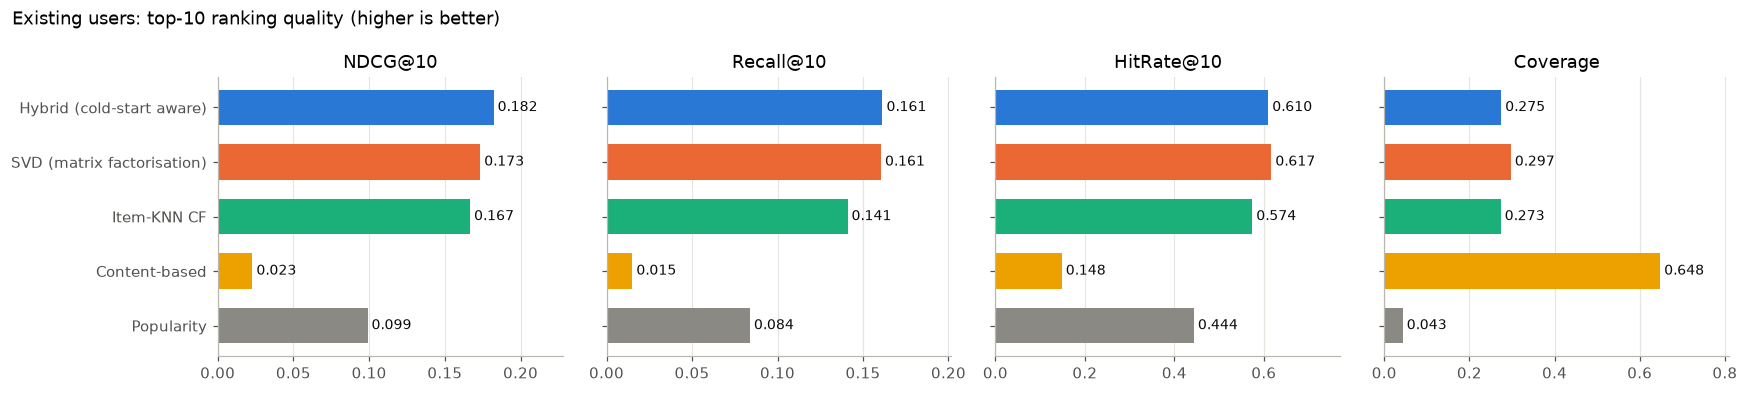

Content-based                NDCG@10 vs baseline: -77%
Item-KNN CF                  NDCG@10 vs baseline: +68%
SVD (matrix factorisation)   NDCG@10 vs baseline: +75%
Hybrid (cold-start aware)    NDCG@10 vs baseline: +84%


In [8]:
order = ["Popularity", "Content-based", "Item-KNN CF", "SVD (matrix factorisation)", "Hybrid (cold-start aware)"]
metrics = ["NDCG@10", "Recall@10", "HitRate@10", "Coverage"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, metric in zip(axes, metrics):
    vals = warm.loc[order, metric]
    ax.barh(range(len(order)), vals, color=[COLORS[m] for m in order], height=0.65)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9, color="#0b0b0b")
    ax.set_title(metric); ax.grid(axis="y", visible=False); ax.set_xlim(0, vals.max() * 1.25)
axes[0].set_yticks(range(len(order)), order)
fig.suptitle("Existing users: top-10 ranking quality (higher is better)", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.savefig(FIG / "warm_users.png", bbox_inches="tight"); plt.show()

base = warm.loc["Popularity", "NDCG@10"]
for m in order[1:]:
    print(f"{m:28s} NDCG@10 vs baseline: {warm.loc[m, 'NDCG@10'] / base - 1:+.0%}")

* Collaborative filtering clearly beats the baseline: the **hybrid improves NDCG@10 by ~84%** over popularity and
  recommends ~6× more of the catalogue (coverage 27% vs 4%).
* Content-based alone is weak at ranking (genres are coarse — "Drama" covers 725 movies) but has the highest coverage
  and novelty; inside the hybrid it adds explainability and helps new users.

## 5. Results — cold start (new users)

In [9]:
cold = evaluate_cold(models, split, ml, k=10)
cold.pivot(index="Known ratings", columns="Model", values="NDCG@10")[order]

Model,Popularity,Content-based,Item-KNN CF,SVD (matrix factorisation),Hybrid (cold-start aware)
Known ratings,,,,,
0,0.3322,0.0000,0.0000,0.0000,0.3494
1,0.3227,0.0541,0.2359,0.1981,0.3257
3,0.3085,0.0650,0.2871,0.2578,0.3472
5,0.2923,0.0620,0.2607,0.2485,0.3341
10,0.2649,0.0707,0.2670,0.2741,0.3265
20,0.2364,0.0641,0.2484,0.2523,0.2767


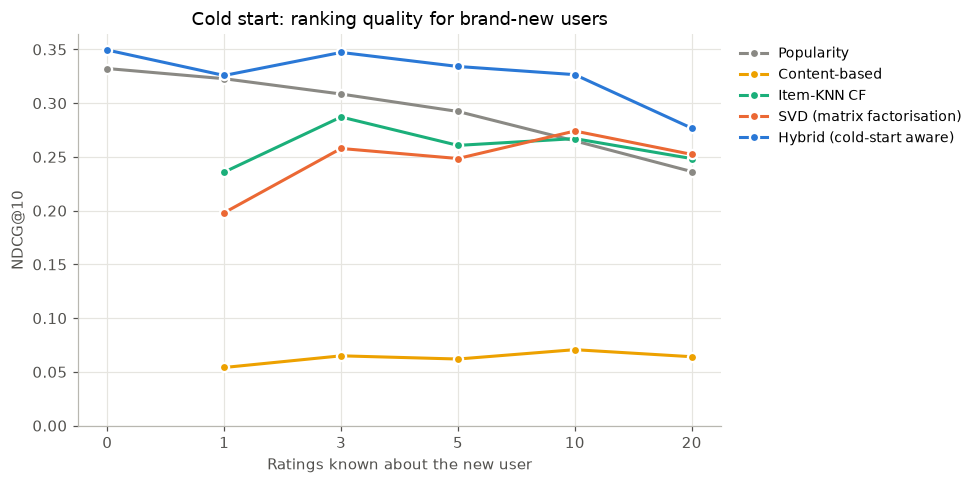

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
piv = cold.pivot(index="Known ratings", columns="Model", values="NDCG@10")
xs = np.arange(len(piv.index))
for m in order:
    y = piv[m].to_numpy()
    mask = piv.index > 0 if m in ("Item-KNN CF", "SVD (matrix factorisation)", "Content-based") else slice(None)
    ax.plot(xs[mask], y[mask], color=COLORS[m], lw=2, marker="o", ms=6,
            markeredgecolor="white", markeredgewidth=1.5, label=m)
ax.set_xticks(xs, piv.index); ax.set_ylim(0, None)
ax.set(xlabel="Ratings known about the new user", ylabel="NDCG@10",
       title="Cold start: ranking quality for brand-new users")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "cold_start.png", bbox_inches="tight"); plt.show()

* **0 ratings:** pure CF/content models have nothing to work with. The hybrid falls back to *demographic popularity*
  (age group × gender) and beats the global popular list.
* **1–10 ratings:** pure CF is unreliable from so little data — below the popularity baseline — while the hybrid
  blends CF in gradually (`a = n/(n+5)`) and is the **best model at every stage**.
* Early MovieLens ratings are mostly blockbusters, which is why popularity is so hard to beat for new users;
  the hybrid keeps a 10% popularity prior for exactly this reason.

## 6. How the hybrid was tuned

A grid of 280 settings (CF model, `n0`, content weight, popularity floor) was scored on **validation data only**:
the newest 10% of existing users' *training* ratings and the tuning half of the new users (`python -m src.tune`).
The objective weighs warm and cold users equally. The test numbers above were never used for any choice.

In [11]:
grid = pd.read_csv(ROOT / "reports" / "tuning_grid.csv")
grid.head(8)[["cf", "n0", "content_weight", "pop_floor", "warm_ndcg", "cold_ndcg", "score"]]

,cf,n0,content_weight,pop_floor,warm_ndcg,cold_ndcg,score
0,svd,5,0.3,0.1,0.1074,0.3492,0.2283
1,svd,10,0.3,0.1,0.1060,0.3494,0.2277
2,svd,5,0.3,0.2,0.1063,0.3489,0.2276
3,svd,5,0.3,0.0,0.1082,0.3464,0.2273
4,svd,5,0.1,0.1,0.1053,0.3490,0.2271
5,svd,10,0.3,0.2,0.1044,0.3496,0.2270
6,svd,3,0.3,0.2,0.1063,0.3475,0.2269
7,svd,20,0.3,0.0,0.1052,0.3479,0.2265


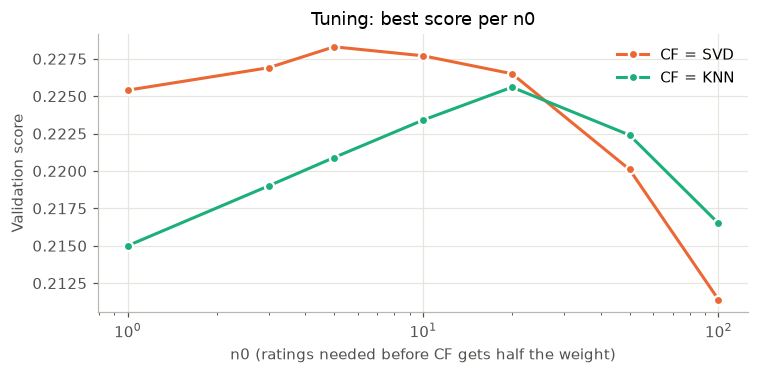

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for cf, color in [("svd", "#eb6834"), ("knn", "#1baf7a")]:
    best = grid[grid.cf == cf].groupby("n0")["score"].max()
    ax.plot(best.index, best.values, color=color, lw=2, marker="o", ms=6,
            markeredgecolor="white", markeredgewidth=1.5, label=f"CF = {cf.upper()}")
ax.set_xscale("log"); ax.set(xlabel="n0 (ratings needed before CF gets half the weight)",
                             ylabel="Validation score", title="Tuning: best score per n0")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / "tuning.png", bbox_inches="tight"); plt.show()

The top configurations score within 0.002 of each other, so the choice is stable rather than a lucky pick.

## 7. Explainability — what users actually see

In [13]:
hybrid = models["Hybrid (cold-start aware)"]
titles = ml.items["title"]

def show(profile, info=None, n=8):
    recs = hybrid.recommend(profile, n, info)
    return pd.DataFrame({"Movie": titles[recs].values,
                         "Genres": [", ".join(ml.items.at[i, "genre_list"]) for i in recs],
                         "Why": [hybrid.explain(profile, i, info) for i in recs]})

uid = 0
g = split.train[split.train.user_id == uid]
profile = dict(zip(g.item_id, g.rating))
print(f"Existing user #{uid + 1}: {len(profile)} ratings, favourite genres:",
      hybrid.content.top_genres(profile))
show(profile)

Existing user #1: 218 ratings, favourite genres: ['Drama', 'Sci-Fi', 'Comedy']


,Movie,Genres,Why
0,Fargo (1996),"Crime, Drama, Thriller",Because you liked “Star Wars (1977)” and “Retu...
1,Monty Python's Life of Brian (1979),Comedy,Because you liked “Monty Python and the Holy G...
2,Shine (1996),"Drama, Romance",Because you liked “Sling Blade (1996)” and “Sh...
3,"English Patient, The (1996)","Drama, Romance, War","Because you liked “Full Monty, The (1997)” and..."
4,Mission: Impossible (1996),"Action, Adventure, Mystery",Because you liked “Toy Story (1995)” and “Retu...
5,Fried Green Tomatoes (1991),Drama,Because you liked “Dead Poets Society (1989)” ...
6,"Truth About Cats & Dogs, The (1996)","Comedy, Romance",Because you liked “Toy Story (1995)” and “Mr. ...
7,True Lies (1994),"Action, Adventure, Comedy, Romance",Because you liked “Jurassic Park (1993)” and “...


In [14]:
new_user = {"age_group": "25-34", "gender": "M", "genres": ["Sci-Fi", "Thriller"]}
print("Brand-new user, 0 ratings, picked Sci-Fi + Thriller at sign-up")
show({}, new_user)

Brand-new user, 0 ratings, picked Sci-Fi + Thriller at sign-up


,Movie,Genres,Why
0,Star Wars (1977),"Action, Adventure, Romance, Sci-Fi, War",Fits your overall taste profile · Matches your...
1,Contact (1997),"Drama, Sci-Fi",Fits your overall taste profile · Matches your...
2,Return of the Jedi (1983),"Action, Adventure, Romance, Sci-Fi, War",Fits your overall taste profile · Matches your...
3,Fargo (1996),"Crime, Drama, Thriller",Fits your overall taste profile · Matches your...
4,Twelve Monkeys (1995),"Drama, Sci-Fi",Fits your overall taste profile · Matches your...
5,"Silence of the Lambs, The (1991)","Drama, Thriller",Fits your overall taste profile · Matches your...
6,Terminator 2: Judgment Day (1991),"Action, Sci-Fi, Thriller",Fits your overall taste profile · Matches your...
7,"Terminator, The (1984)","Action, Sci-Fi, Thriller",Fits your overall taste profile · Matches your...


In [15]:
few = {ml.items.index[ml.items.title == "Toy Story (1995)"][0]: 5,
       ml.items.index[ml.items.title == "Lion King, The (1994)"][0]: 5,
       ml.items.index[ml.items.title == "Aladdin (1992)"][0]: 4}
print("New user after rating 3 animated movies")
show(few, {"age_group": "18-24", "gender": "F"})

New user after rating 3 animated movies


,Movie,Genres,Why
0,Liar Liar (1997),Comedy,Because you liked “Toy Story (1995)” · Matches...
1,Beauty and the Beast (1991),"Animation, Children's, Musical","Because you liked “Lion King, The (1994)” and ..."
2,Snow White and the Seven Dwarfs (1937),"Animation, Children's, Musical","Because you liked “Lion King, The (1994)” and ..."
3,Scream (1996),"Horror, Thriller",Because you liked “Toy Story (1995)” · Popular...
4,Cinderella (1950),"Animation, Children's, Musical","Because you liked “Lion King, The (1994)” and ..."
5,Return of the Jedi (1983),"Action, Adventure, Romance, Sci-Fi, War",Because you liked “Toy Story (1995)” and “Alad...
6,Fantasia (1940),"Animation, Children's, Musical","Because you liked “Lion King, The (1994)” and ..."
7,Star Wars (1977),"Action, Adventure, Romance, Sci-Fi, War",Because you liked “Toy Story (1995)” · Popular...


## 8. Conclusions

| Requirement | Where it is handled |
|---|---|
| Popularity baseline | `PopularityRecommender`; every table compares against it |
| Content-based / collaborative filtering | `ContentBasedRecommender`, `ItemKNNRecommender`, `SVDRecommender` |
| Cold-start handling | Hybrid with demographic popularity + sign-up genres, CF weight growing with ratings; new movies can be ranked by the content model |
| Ranking metrics | Precision, Recall, NDCG, MAP, HitRate @10 + coverage + novelty |
| Explainability | Every recommendation has a "because you liked …" / genre / popularity reason |
| Simple demo | `streamlit run app.py` |

**Limitations & next steps:** offline metrics only (no online A/B test); MovieLens 100K is small and dated;
popularity bias in the data favours blockbusters; next steps would be implicit-feedback models (ALS/BPR),
text features (plot descriptions) for the content model, and diversity-aware re-ranking.